# Search-Attention Signal in the S&P 100
### Can Investor Attention Be Traded? 

- **Pattern:** stocks whose weekly Google search interest jumps well above their own norm tend to earn different excess returns over the following two weeks than stocks with no spike.
- **Why it might be true:** limited-attention theory. A search spike proxies for a surge of investor attention, and attention-driven buying can move prices before fundamentals do. Da, Engelberg & Gao (2011), *In Search of Attention*, Journal of Finance, report that abnormal search volume is followed by higher prices over roughly the next two weeks and a reversal over the following year.
- **What would prove it wrong:** the excess-return gap between spike and non-spike weeks is indistinguishable from zero in both sub-periods, or the strategy fails to beat an equal-weighted basket of the same stocks after costs.


**How this notebook is organised** (same order as the report): 2 data acquisition, 3 data cleaning, 4 strategy, 5 backtest, 6 risk diagnostics.

**Reproducibility.** Raw data is pulled once and saved in `data/`. With `USE_CACHE = True` every later run loads that snapshot, so the numbers do not change. Google Trends returns slightly different values on each fresh pull. To re-pull, delete the files in `data/`.

## 1. Setup and parameters

This section sets the main rules of my test. I deem a search spike as a Google Trends z-score above 2, meaning searches are unusually high compared with that company’s own past.

I use a 52-week window because it gives one year of past search data. I hold each stock for two weeks because previous research finds that attention can affect prices over approximately the following two weeks. I then exit after two weeks regardless of whether the price rises or falls before then. This keeps the rule consistent and avoids choosing a stop-loss after seeing the results.

I delay the signal by 14 days because a Google Trends week is not fully available when that week’s stock market closes. I also include a cost of 5 basis points when buying and another 5 basis points when selling.

The split date separates the data into two periods so I can see whether the result is similar over time. Because i examined both periods while building the project so the second period is a stability check

In [ ]:
import time
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

SPIKE_Z      = 2.0     # spike = weekly search index more than 2 std above its own trailing norm
ROLL_WEEKS   = 52      # trailing window for the norm (includes the current week, which is conservative)
MIN_WEEKS    = 26      # minimum history before a z-score is computed
LAG_DAYS     = 14      # a Trends week runs Sun-Sat; we act at the Friday close of the following week
HOLD_WEEKS   = 2       # holding period, taken from the attention literature
COST_PER_LEG = 0.0005  # 5 bps per buy or sell
SPLIT_DATE   = pd.Timestamp("2024-06-01")   # two sub-periods; nothing is fitted on either one

TRENDS_START, TRENDS_END = "2021-10-01", "2026-09-01"   # under 5 years, so Google returns WEEKLY data
PRICE_START,  PRICE_END  = "2021-09-01", "2026-09-01"

DATA_DIR, FIG_DIR = Path("data"), Path("figures")
DATA_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
USE_CACHE = True

def log_source(text):
    with open(DATA_DIR / "SOURCES.txt", "a") as f:
        f.write(f"[{datetime.now():%Y-%m-%d %H:%M}] {text}\n")

## 2. Data acquisition

### 2.1 Universe
The 101 constituents of the S&P 100 (Alphabet has two share classes), cross-checked on 2026-09-22 against Wikipedia's S&P 100 page and the published holdings of the iShares S&P 100 ETF (OEF); both lists matched.

**Limitation to carry into the report:** this is *today's* membership applied to the whole sample (survivorship / look-ahead in universe selection). The bias probably flatters both the strategy and the benchmark; comparing against a benchmark built from the same stocks partly offsets it. GOOG and GOOGL are the same company but have different search terms, so they are kept as separate rows.


In [ ]:
# Map each stock ticker to the company name used as its Google search term
sp100 = {
    "AAPL": "Apple", "ABBV": "AbbVie", "ABT": "Abbott Laboratories", "ACN": "Accenture",
    "ADBE": "Adobe", "AMAT": "Applied Materials", "AMD": "AMD", "AMGN": "Amgen",
    "AMT": "American Tower", "AMZN": "Amazon", "ANET": "Arista Networks", "AVGO": "Broadcom",
    "AXP": "American Express", "BA": "Boeing", "BAC": "Bank of America", "BKNG": "Booking Holdings",
    "BLK": "BlackRock", "BMY": "Bristol Myers Squibb", "BNY": "BNY Mellon", "BRK-B": "Berkshire Hathaway",
    "C": "Citigroup", "CAT": "Caterpillar", "CMCSA": "Comcast", "COF": "Capital One",
    "COP": "ConocoPhillips", "COST": "Costco", "CRM": "Salesforce", "CSCO": "Cisco",
    "CVS": "CVS Health", "CVX": "Chevron", "DE": "Deere", "DELL": "Dell Technologies",
    "DHR": "Danaher", "DIS": "Disney", "DUK": "Duke Energy", "EMR": "Emerson Electric",
    "FDX": "FedEx", "GD": "General Dynamics", "GE": "GE Aerospace", "GEV": "GE Vernova",
    "GILD": "Gilead Sciences", "GM": "General Motors", "GOOG": "Alphabet", "GOOGL": "Alphabet Inc",
    "GS": "Goldman Sachs", "HD": "Home Depot", "IBM": "IBM", "INTC": "Intel",
    "INTU": "Intuit", "ISRG": "Intuitive Surgical", "JNJ": "Johnson and Johnson", "JPM": "JPMorgan Chase",
    "KO": "Coca-Cola", "LIN": "Linde", "LLY": "Eli Lilly", "LMT": "Lockheed Martin",
    "LOW": "Lowes", "LRCX": "Lam Research", "MA": "Mastercard", "MCD": "McDonalds",
    "MDLZ": "Mondelez", "MDT": "Medtronic", "META": "Meta Platforms", "MMM": "3M",
    "MO": "Altria", "MRK": "Merck", "MS": "Morgan Stanley", "MSFT": "Microsoft",
    "MU": "Micron Technology", "NEE": "NextEra Energy", "NFLX": "Netflix", "NOW": "ServiceNow",
    "NVDA": "Nvidia", "ORCL": "Oracle", "PANW": "Palo Alto Networks", "PEP": "PepsiCo",
    "PFE": "Pfizer", "PG": "Procter and Gamble", "PLTR": "Palantir Technologies", "PM": "Philip Morris",
    "QCOM": "Qualcomm", "RTX": "RTX Corporation", "SBUX": "Starbucks", "SCHW": "Charles Schwab",
    "SNDK": "Sandisk", "SO": "Southern Company", "T": "AT&T", "TMO": "Thermo Fisher Scientific",
    "TMUS": "T-Mobile", "TSLA": "Tesla", "TXN": "Texas Instruments", "UBER": "Uber",
    "UNH": "UnitedHealth Group", "UNP": "Union Pacific", "UPS": "UPS", "USB": "US Bancorp",
    "V": "Visa", "VZ": "Verizon", "WFC": "Wells Fargo", "WMT": "Walmart", "XOM": "ExxonMobil",
}

# Save the exact universe used so the analysis can be reproduced
pd.Series(sp100, name="search_term").rename_axis("ticker").to_csv(DATA_DIR / "universe.csv")
print(f"Universe: {len(sp100)} tickers")

Universe: 101 tickers


### 2.2 Google Trends (weekly)
Google returns weekly data only for windows under about five years. Each term is requested on its own, so the 0-100 index is scaled within that term's own history. Because a z-score is unaffected by multiplying a series by a constant, that scaling does not matter for the signal; the integer rounding of the index is a minor limitation.

The pull is rate-limited by Google, so it sleeps between requests and retries failures with longer pauses. The last and incomplete week is dropped.

I download each company separately, so raw Google Trends values cannot be compared directly across companies. A value of 80 for Apple is not necessarily the same amount of attention as 80 for Tesla. It only means that searches are high compared with that company’s own maximum.

This is why I later compare each company with its own past using a z-score. I also save the first download because Google may rescale the values if I request them again.

In [ ]:
# Download one weekly search series for every company in the universe
def pull_trends_weekly(universe, start, end, max_rounds=4):
    from pytrends.request import TrendReq          # imported here so the notebook runs from the snapshot alone
    pt = TrendReq(hl="en-US", tz=360)
    series, pending = {}, list(universe)
    
    # Retry failed requests because Google can temporarily reject or limit requests
    for rnd in range(max_rounds):
        failed = []
        for tkr in pending:
            term = universe[tkr]
            try:
                pt.build_payload([term], timeframe=f"{start} {end}", geo="US")
                df = pt.interest_over_time()
                if df.empty or term not in df.columns:
                    failed.append(tkr)
                else:
                    if "isPartial" in df.columns:
                        df = df[~df["isPartial"].astype(bool)]    # drop the incomplete latest week
                    series[tkr] = df[term].astype(float)
            except Exception:
                failed.append(tkr)
            time.sleep(2 + 3 * rnd)     # pause between requests to reduce the chance of being rate-limited
        pending = failed
        print(f"round {rnd + 1}: {len(series)} pulled, {len(pending)} pending")
        if not pending:
            break
    return pd.DataFrame(series), pending

# using the saved snapshot unless a new download is required
trends_file = DATA_DIR / "trends_weekly.csv"
if USE_CACHE and trends_file.exists():
    trends_raw = pd.read_csv(trends_file, index_col=0, parse_dates=True)
    print(f"Loaded Trends snapshot: {trends_raw.shape[1]} tickers, {trends_raw.shape[0]} weeks")
else:
    trends_raw, trends_failed = pull_trends_weekly(sp100, TRENDS_START, TRENDS_END)
    trends_raw.to_csv(trends_file)
    log_source(f"Google Trends via pytrends, weekly, geo=US, {TRENDS_START} to {TRENDS_END}; "
               f"{trends_raw.shape[1]} of {len(sp100)} terms; failed: {trends_failed}")
    print("Failed after all retries:", trends_failed)

round 1: 99 pulled, 2 pending
round 2: 101 pulled, 0 pending
Failed after all retries: []


The cached file makes the analysis reproducible because every later run uses the same search values. The download is the slowest part of the notebook because it makes 101 separate requests and deliberately waits between them.

### 2.3 Prices (Yahoo Finance via yfinance)
Daily closes, adjusted for splits and dividends (`auto_adjust=True`). Tickers that fail in the bulk download are retried one at a time.

I use adjusted closing prices because they account for stock splits and dividends. Without this, a split or dividend could appear to be an ordinary price loss.

The data is downloaded daily and converted into weekly prices later so that it can be matched with the weekly Google Trends observations.

In [5]:
def pull_prices(tickers, start, end):
    import yfinance as yf
    raw = yf.download(list(tickers), start=start, end=end, progress=False, auto_adjust=True)["Close"]
    missing = [t for t in tickers if t not in raw.columns or raw[t].dropna().empty]
    for t in missing:
        s = yf.download(t, start=start, end=end, progress=False, auto_adjust=True)["Close"]
        if isinstance(s, pd.DataFrame):
            s = s.iloc[:, 0]
        if s.dropna().size:
            raw[t] = s
    return raw

prices_file = DATA_DIR / "prices_daily.csv"
if USE_CACHE and prices_file.exists():
    prices_raw = pd.read_csv(prices_file, index_col=0, parse_dates=True)
    print(f"Loaded price snapshot: {prices_raw.shape[1]} tickers, {prices_raw.shape[0]} days")
else:
    prices_raw = pull_prices(list(sp100), PRICE_START, PRICE_END)
    prices_raw.to_csv(prices_file)
    log_source(f"Daily adjusted closes via yfinance, {PRICE_START} to {PRICE_END}; {prices_raw.shape[1]} tickers")

The downloaded prices start slightly earlier than the Google Trends data. This gives the code enough price history to calculate the first weekly returns and match them with the first usable search signals.

## 3. Data cleaning
The price and search datasets use different frequencies and date conventions so first i had to sort the dates, remove duplicates and convert daily prices into weekly closing prices.

 also check that the Google Trends observations are exactly 7 days apart. This was important because my first download covered more than five years, causing Google to return monthly values that my earlier code treated as weekly. (bc i am holding for 2 weeks so i need weekly)

In [ ]:
#  3.1 drop empty tickers, convert to weekly closes .....
prices_daily = prices_raw.copy()
prices_daily.index = pd.to_datetime(prices_daily.index)
prices_daily = prices_daily[~prices_daily.index.duplicated()].sort_index()

empty = [c for c in prices_daily.columns if prices_daily[c].dropna().empty]
prices_daily = prices_daily.drop(columns=empty)
print("Tickers with no price data at all (dropped):", empty or "none")

weekly_prices = prices_daily.resample("W-SUN").last()     # last trading close of each Mon-Sun week, labelled by the Sunday
# drop a trailing week that is not complete (its Friday close would be missing)
if weekly_prices.index[-1] - prices_daily.index.max() > pd.Timedelta(days=2):
    weekly_prices = weekly_prices.iloc[:-1]
    print("Dropped an incomplete final price week")

first_valid = weekly_prices.apply(lambda s: s.first_valid_index())
late = first_valid[first_valid > pd.Timestamp(PRICE_START) + pd.Timedelta(days=30)]
print("Tickers whose price history starts after the sample start (returns are NaN before this, never zero-filled):")
print(late.dt.date.to_string() if len(late) else "none")

# 3.2 Trends: make the weekly grid explicit.......
trends = trends_raw.copy()
trends.index = pd.to_datetime(trends.index)
trends = trends.sort_index()
full_idx = pd.date_range(trends.index.min(), trends.index.max(), freq="7D")
assert trends.index.isin(full_idx).all(), "Trends dates are not on a clean 7-day grid; this is not weekly data"
n_missing_weeks = len(full_idx) - len(trends.index)
trends = trends.reindex(full_idx)                          # a missing week becomes an explicit NaN, never filled
print(f"Trends: {trends.shape[1]} terms, {trends.shape[0]} weekly rows, {n_missing_weeks} missing weeks")
print("Median gap between observations (days):", trends.index.to_series().diff().dt.days.median(), "(must be 7)")

low_volume = trends.median()[lambda s: s < 5]
print("Terms with a median search index below 5 (z-scores are noisy for these):", list(low_volume.index) or "none")

# 3.3 Align the two sources......
tickers = [t for t in trends.columns if t in weekly_prices.columns]
dropped = sorted(set(sp100) - set(tickers))
trends, px = trends[tickers], weekly_prices[tickers]
print(f"\nFinal universe: {len(tickers)} tickers. Dropped for missing data: {dropped or 'none'}")
print("Splits and dividends are handled by auto_adjust=True in the price download.")

Tickers with no price data at all (dropped): none
Dropped an incomplete final price week
Tickers whose price history starts after the sample start (returns are NaN before this, never zero-filled):
Ticker
GEV     2024-03-31
SNDK    2025-02-16
Trends: 101 terms, 258 weekly rows, 0 missing weeks
Median gap between observations (days): 7.0 (must be 7)
Terms with a median search index below 5 (z-scores are noisy for these): ['AMT']

Final universe: 101 tickers. Dropped for missing data: none
Splits and dividends are handled by auto_adjust=True in the price download.


The median gap of 7 days confirms that the final Google Trends data is weekly.  yhis check helped me find the main error in my earlier version, where monthly observations had accidentally been treated as weekly.

Companies with shorter price histories remain missing until prices become available. Their earlier returns are not created or filled during signal construction.

## 4. Strategy

### 4.1 The signal
For each stock and Trends week, the z score compares that week's search index with its own trailing 52-week mean and standard deviation. A **spike** is z > 2.

The current observation is included in the rolling mean and standard deviation.  making the spike rule slightly harder to pass because an unusually high observation increases its own average and volatility.

**Timings.** A Trends week runs Sunday to Saturday, so its value is not known until the following Sunday. The z-score is therefore re-dated 14 days later, which is the Friday close of the week *after* the search week. That leaves a full week of slack. Everything in this notebook acts only on information available at that date. Forward returns are measured from that close.

In [7]:
def build_z(trends, target_index):
    mu = trends.rolling(ROLL_WEEKS, min_periods=MIN_WEEKS).mean()
    sd = trends.rolling(ROLL_WEEKS, min_periods=MIN_WEEKS).std()
    z = ((trends - mu) / sd).replace([np.inf, -np.inf], np.nan)
    z.index = z.index + pd.Timedelta(days=LAG_DAYS)      # date the signal is actually known
    return z.reindex(target_index)

# Alignment check: every signal date must land on the weekly price grid.
on_grid = (trends.index + pd.Timedelta(days=LAG_DAYS)).isin(px.index).mean()
print(f"Share of signal dates that land on the weekly price grid: {on_grid:.0%}")
assert on_grid > 0.9, "Signals and prices are not on the same weekly grid"

z_all = build_z(trends, px.index)
wk_ret = px / px.shift(1) - 1                                  # weekly return of each stock
spike_flags = (z_all > SPIKE_Z) & px.notna()
print(f"Spike signals: {int(spike_flags.sum().sum())} across {int((spike_flags.sum() > 0).sum())} stocks")

Share of signal dates that land on the weekly price grid: 99%
Spike signals: 1370 across 101 stocks


The alignment check confirms that the delayed signal dates match the weekly price dates. This prevents the code from connecting a search spike with the wrong return period.

The total number of signals is also a check for basically if almost every stock week were classified as a spike, the rule would not be identifying genuinely unusual attention.

In [8]:
# Check on the one low-volume term flagged in section 3 (AMT): is it producing an unusual number of spikes?
print(int(spike_flags["AMT"].sum()), "AMT spikes vs median", spike_flags.sum().median(), "per stock")

20 AMT spikes vs median 13.0 per stock


American Tower produces more spikes than the median stock, but it is not one of the largest contributors to the strategy’s return. I therefore keep it in the sample while acknowledging that its low search volume makes its signal less precise.

Alphabet has two share classes with different search terms ("Alphabet" and "Alphabet Inc"). theyre the same company, so their search series should move together. How closely they do is a direct measure of how noisy company-name searches are.

In [9]:
print("GOOG vs GOOGL search correlation:", round(trends["GOOG"].corr(trends["GOOGL"]), 2))

GOOG vs GOOGL search correlation: 0.48


The two search series represent the same company but are not perfectly correlated. This shows that the exact company name used in Google Trends can affect the search values and introduces measurement noise.

### 4.2 Event study: do spike stocks beat the rest?
For each week, take the forward return over the next `HOLD_WEEKS`, subtract that week's average across all stocks (this strips out the market move), and compare stocks with a spike to stocks without one.

**Two t-statistics are printed, and only one should be trusted.** The pooled t-stat treats every stock-week as an independent observation. Stocks spike together and the two-week windows overlap, so it is badly overstated. The *weekly HAC* t-stat collapses each week to one number (spike average minus non-spike average) and corrects for overlap. 

Comparing spike and non-spike stocks in the same week helps separate the search effect from general market movements, so for example, if most of the stocks rise because of marketwide news, i dont want to treat that whole rise as evidence that search attention worked.

In [10]:
def hac_t(x, lags):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) < lags + 3:
        return np.nan
    return sm.OLS(x, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": lags}).tvalues[0]

def gap_series(z, px, hold, thr):
    fwd = px.shift(-hold) / px - 1
    valid = z.notna() & fwd.notna()
    f = fwd.where(valid)
    excess = f.sub(f.mean(axis=1), axis=0)                      # remove the market-wide component each week
    is_spike = (z > thr) & valid
    is_other = (~(z > thr)) & valid
    s, o = excess.where(is_spike), excess.where(is_other)
    diff = (s.mean(axis=1) - o.mean(axis=1)).dropna()           # one number per week that had a spike
    return {"diff": diff, "s": s, "o": o, "f_s": f.where(is_spike), "f_o": f.where(is_other)}

def by_period(idx):
    return {"in-sample": idx < SPLIT_DATE, "out-of-sample": idx >= SPLIT_DATE}

def summarize_gap(z, px, hold, thr):
    g = gap_series(z, px, hold, thr)
    rows = []
    for label, m in by_period(g["diff"].index).items():
        d = g["diff"][m]
        n_spike = int(g["s"].loc[g["s"].index < SPLIT_DATE if label == "in-sample" else g["s"].index >= SPLIT_DATE].notna().sum().sum())
        rows.append({"period": label, "weeks_with_spikes": len(d), "spike_obs": n_spike,
                     "mean_gap": d.mean(), "median_gap": d.median(), "hac_t": hac_t(d, hold)})
    return pd.DataFrame(rows)

primary = summarize_gap(z_all, px, HOLD_WEEKS, SPIKE_Z)
print(f"PRIMARY SPECIFICATION: spike z > {SPIKE_Z}, hold {HOLD_WEEKS} weeks (fixed in advance)")
print("mean_gap = average excess return of spike stocks minus non-spike stocks, per spike week\n")
print(primary.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

g = gap_series(z_all, px, HOLD_WEEKS, SPIKE_Z)
print("\nComparison with the naive pooled t-stat (do NOT report this one):")
for label, mask_fn in [("in-sample", lambda i: i < SPLIT_DATE), ("out-of-sample", lambda i: i >= SPLIT_DATE)]:
    sp = g["s"].loc[mask_fn(g["s"].index)].to_numpy().ravel(); sp = sp[~np.isnan(sp)]
    ot = g["o"].loc[mask_fn(g["o"].index)].to_numpy().ravel(); ot = ot[~np.isnan(ot)]
    fs = g["f_s"].loc[mask_fn(g["f_s"].index)].to_numpy().ravel(); fs = fs[~np.isnan(fs)]
    fo = g["f_o"].loc[mask_fn(g["f_o"].index)].to_numpy().ravel(); fo = fo[~np.isnan(fo)]
    t_naive = stats.ttest_ind(sp, ot, equal_var=False).statistic if len(sp) > 1 and len(ot) > 1 else np.nan
    print(f"  {label}: mean forward return spike {fs.mean():.2%} vs non-spike {fo.mean():.2%} | naive pooled t = {t_naive:.2f}")

PRIMARY SPECIFICATION: spike z > 2.0, hold 2 weeks (fixed in advance)
mean_gap = average excess return of spike stocks minus non-spike stocks, per spike week

       period  weeks_with_spikes  spike_obs  mean_gap  median_gap  hac_t
    in-sample                108        406    0.0062      0.0000 1.6520
out-of-sample                114        961    0.0054      0.0011 1.2182

Comparison with the naive pooled t-stat (do NOT report this one):
  in-sample: mean forward return spike 1.21% vs non-spike 0.51% | naive pooled t = 1.75
  out-of-sample: mean forward return spike 1.76% vs non-spike 0.96% | naive pooled t = 3.81


The mean gap tells me whether spike stocks performed better or worse than non spike stocks. also the HAC t-statistic is for whether that difference is estimated precisely enough to be convincing.

In the out-of-sample period, treating every stock week as an independent observation produced a pooled t-statistic of 3.81 and once i counted each week once and used a Newey–West HAC test to account for stocks spiking together and overlapping two-week returns, the t-statistic fell to 1.22. 

I therefore report the weekly HAC result because it gives a more honest measure of the evidence.


### 4.3 Robustness grid 
Nine combinations of threshold and holding period.

Here the purpose is not to find a better performing version of the strategy, but to check whether the result changes completely when i make reasonable changes to the spike threshold or holding period. 

In [11]:
grid_rows = []
for thr in [1.5, 2.0, 2.5]:
    for hold in [1, 2, 4]:
        res = summarize_gap(z_all, px, hold, thr)
        res.insert(0, "hold_weeks", hold); res.insert(0, "spike_z", thr)
        grid_rows.append(res)
grid = pd.concat(grid_rows, ignore_index=True)
print(grid.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print(f"\nSpecifications where the weekly HAC t-stat is above 2: {(grid['hac_t'].abs() > 2).sum()} of {len(grid)} (period-spec rows)")

 spike_z  hold_weeks        period  weeks_with_spikes  spike_obs  mean_gap  median_gap   hac_t
  1.5000           1     in-sample                113        784    0.0008      0.0008  0.5391
  1.5000           1 out-of-sample                117       1572    0.0018      0.0012  1.0588
  1.5000           2     in-sample                113        784    0.0025      0.0002  0.9807
  1.5000           2 out-of-sample                116       1567    0.0009     -0.0002  0.3328
  1.5000           4     in-sample                113        784    0.0026      0.0045  0.7358
  1.5000           4 out-of-sample                114       1561    0.0050     -0.0005  0.8290
  2.0000           1     in-sample                108        406    0.0043      0.0034  1.6160
  2.0000           1 out-of-sample                115        963    0.0035      0.0026  1.3118
  2.0000           2     in-sample                108        406    0.0062      0.0000  1.6520
  2.0000           2 out-of-sample                

## 5. Backtest
**Rules, that i set in advance:** 
at each weekly close, buy every stock with a spike signal, equal-weighted, and hold for `HOLD_WEEKS` weeks. Capital is split into `HOLD_WEEKS` equal sleeves, one per weekly cohort, so the portfolio is fully invested only when cohorts exist. An empty sleeve sits in cash earning zero. There is no stop-loss, no filter and no re-entry rule. If a weekly return is missing while a position is open, the backtest treats it as zero so that a missing value does not break the portfolio calculation. This is a simplifying assumption and could understate either a gain or a loss.

**Costs:** 5
 bps on every buy and every sell of a cohort's notional. Overlap between cohorts is not netted, which is slightly conservative.

**Benchmark:** 
an equal-weighted, weekly-rebalanced basket of the same stocks, with no costs. Because it uses the same (survivor-biased) universe, the comparison partly cancels that bias.

**Sharpe ratios** 
use a zero risk-free rate and 52 weeks per year.

The 2 sleeves are needed because new positions can be opened every week while the previous week’s positions are still being held. Half of the capital is allocated to each group.

Every position is sold after two weeks, even if its price falls before then. This directly tests my two-week hypothesis. Adding a stop-loss would create another rule and threshold that could be chosen after seeing the data.

In [12]:
def run_backtest(sig, weekly_returns, hold, cost):
    rets0 = weekly_returns.fillna(0.0)
    contrib = pd.DataFrame(0.0, index=sig.index, columns=sig.columns)
    invested = pd.Series(0.0, index=sig.index)
    for k in range(1, hold + 1):
        cohort = sig.shift(k, fill_value=False)                  # stocks bought k weeks ago
        n = cohort.sum(axis=1)
        w = cohort.astype(float).div(n.where(n > 0), axis=0).fillna(0.0) / hold
        contrib += w * rets0                                      # weight x this week's return
        invested += (n > 0).astype(float) / hold
    nonempty = sig.any(axis=1).astype(float)
    buy  = nonempty * cost / hold                                 # paid at the signal-date close
    sell = nonempty.shift(hold, fill_value=0.0) * cost / hold     # paid HOLD weeks later
    gross = contrib.sum(axis=1)
    return {"net": gross - buy - sell, "gross": gross, "contrib": contrib, "invested": invested}

def perf(r):
    r = r.dropna()
    cum = (1 + r).cumprod()
    path = np.r_[1.0, cum.values]                      # start from 1.0 so an early loss counts
    return {"weeks": len(r), "total_return": cum.iloc[-1] - 1,
            "ann_return": cum.iloc[-1] ** (52 / len(r)) - 1,
            "ann_vol": r.std() * np.sqrt(52),
            "sharpe": r.mean() / r.std() * np.sqrt(52),
            "max_drawdown": (path / np.maximum.accumulate(path) - 1).min()}

bt = run_backtest(spike_flags, wk_ret, HOLD_WEEKS, COST_PER_LEG)
bench = wk_ret.mean(axis=1)

first_signal = spike_flags.any(axis=1).idxmax()
last_week = px.index[-1]
periods = {"in-sample": (first_signal, SPLIT_DATE - pd.Timedelta(days=1)),
           "out-of-sample": (SPLIT_DATE, last_week)}

rows = {}
for label, (a, b) in periods.items():
    rows[f"strategy, net of costs ({label})"] = perf(bt["net"].loc[a:b])
    rows[f"strategy, before costs ({label})"] = perf(bt["gross"].loc[a:b])
    rows[f"benchmark ({label})"] = perf(bench.loc[a:b])
    print(f"{label}: average share of capital invested = {bt['invested'].loc[a:b].mean():.0%}")
results = pd.DataFrame(rows).T
print()
print(results.to_string(float_format=lambda v: f"{v:.3f}"))

print("\nStrategy minus benchmark (weekly active return), HAC t-stat with overlap correction:")
for label, (a, b) in periods.items():
    active = (bt["net"] - bench).loc[a:b].dropna()
    print(f"  {label}: mean {active.mean() * 52:.2%} per year, t = {hac_t(active, HOLD_WEEKS):.2f}")

in-sample: average share of capital invested = 95%
out-of-sample: average share of capital invested = 97%

                                         weeks  total_return  ann_return  ann_vol  sharpe  max_drawdown
strategy, net of costs (in-sample)     113.000         0.590       0.238    0.250   0.975        -0.201
strategy, before costs (in-sample)     113.000         0.677       0.269    0.250   1.074        -0.196
benchmark (in-sample)                  113.000         0.297       0.127    0.178   0.760        -0.197
strategy, net of costs (out-of-sample) 118.000         1.088       0.383    0.193   1.785        -0.143
strategy, before costs (out-of-sample) 118.000         1.212       0.419    0.193   1.917        -0.137
benchmark (out-of-sample)              118.000         0.771       0.286    0.140   1.868        -0.146

Strategy minus benchmark (weekly active return), HAC t-stat with overlap correction:
  in-sample: mean 10.87% per year, t = 1.22
  out-of-sample: mean 8.14% per yea

The strategy beats the all-stock benchmark in **both** periods after transaction costs. BUT, the t-statistics for its return above the benchmark are below 1.96.

This means the result is economically positive but NOT statistically significant at the 5% level. The high cumulative return by itself is not enough to prove that Google Trends created a reliable trading advantage.

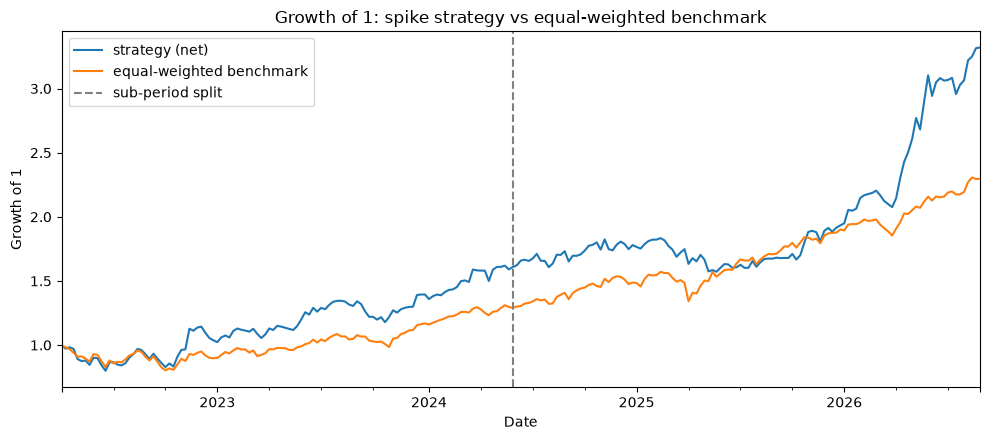

In [13]:
growth = pd.DataFrame({"strategy (net)": (1 + bt["net"].loc[first_signal:]).cumprod(),
                       "equal-weighted benchmark": (1 + bench.loc[first_signal:]).cumprod()})
ax = growth.plot(figsize=(10, 4.5), title="Growth of 1: spike strategy vs equal-weighted benchmark")
ax.axvline(SPLIT_DATE, color="grey", linestyle="--", label="sub-period split")
ax.set_ylabel("Growth of 1"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "cumulative_return.png", dpi=150); plt.show()

here the graph shows that the strategy and benchmark often move in the same direction. suggesting that part of the strategy’s return comes from ordinary market exposure rather than from a completely independent attention effect.

### 5.2 Good-news variant: buy a spike only if the price also rose (added after the main result)

Can we avoid stocks that are trending for the wrong reasons?

- **Good-news spike:** a spike signal where the stock's price **rose during the search week** itself (the Monday-to-Friday price week that matches the Sunday-to-Saturday Trends week behind the signal). That return is known by the Friday close of the search week, a week before the signal date, so it uses nothing from the future.
- **Bad-news spike:** a spike where the price fell (or did not rise) in the search week.
- **"Buy immediately":** with weekly Trends data a week is only complete on the Sunday after it ends, so the earliest honest entry on the weekly grid is the Friday close of the following week. That is the same entry date as the baseline strategy, so the two differ only by the filter.

Everything else (hold, costs, benchmark, split date) is identical to section 5. This was run **after** the baseline result, as an extra variant.

Once a good-news signal is selected, hold it for the same fixed 2-week period. i DONT sell early if the price falls because that would create a different strategy and would require choosing a stop-loss rule. (remember i am bascally testing Da, Engelberg and Gao 2011 that find that a rise in a stock's searches predicts **higher prices over the next two weeks**)

Signals: all spikes 1370 | good-news spikes 703 | bad-news spikes 665
Share of spikes where the price rose in the search week: 51.3% (for comparison, 53.2% of all stock-weeks rise)
Truncation check on the good-news flag: 0 differences

Backtest, good-news variant (net of costs unless stated), against the baseline and the benchmark:
  in-sample: average share of capital invested = 71%
  out-of-sample: average share of capital invested = 89%
                                                   weeks  total_return  ann_return  ann_vol  sharpe  max_drawdown
good-news strategy, net (in-sample)              113.000         0.517       0.211    0.217   0.989        -0.179
good-news strategy, before costs (in-sample)     113.000         0.579       0.234    0.218   1.073        -0.175
all-spikes strategy, net (in-sample)             113.000         0.590       0.238    0.250   0.975        -0.201
benchmark (in-sample)                            113.000         0.297       0.127    0.178   0.760 

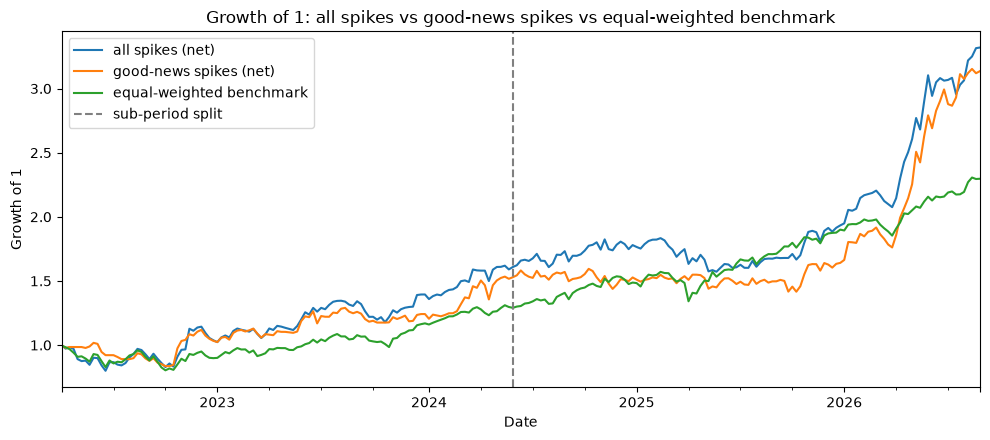

In [14]:
search_week_ret = wk_ret.shift(1)       # return of the price week matching the Trends week behind each signal (known before the signal date)
good_news = search_week_ret > 0
spike_good = spike_flags & good_news
spike_bad = spike_flags & ~good_news & search_week_ret.notna()
print(f"Signals: all spikes {int(spike_flags.sum().sum())} | good-news spikes {int(spike_good.sum().sum())} | bad-news spikes {int(spike_bad.sum().sum())}")
print(f"Share of spikes where the price rose in the search week: {(spike_flags & good_news).sum().sum() / spike_flags.sum().sum():.1%} "
      f"(for comparison, {(good_news & px.notna()).sum().sum() / px.notna().sum().sum():.1%} of all stock-weeks rise)")

# No-look-ahead check: the good-news flag must not change if all prices after the signal date are deleted
n_bad = 0
for cut in pd.to_datetime(["2023-03-05", "2024-06-02", "2025-05-04", "2026-02-01"]):
    pc = px.loc[:cut]
    g_cut = ((pc / pc.shift(1) - 1).shift(1) > 0)
    both = search_week_ret.loc[:cut].notna().to_numpy()
    n_bad += int((g_cut.to_numpy()[both] != good_news.loc[:cut].to_numpy()[both]).sum())
print(f"Truncation check on the good-news flag: {n_bad} differences")

bt_good = run_backtest(spike_good, wk_ret, HOLD_WEEKS, COST_PER_LEG)
print("\nBacktest, good-news variant (net of costs unless stated), against the baseline and the benchmark:")
rows_g = {}
for label, (a_, b_) in periods.items():
    rows_g[f"good-news strategy, net ({label})"] = perf(bt_good["net"].loc[a_:b_])
    rows_g[f"good-news strategy, before costs ({label})"] = perf(bt_good["gross"].loc[a_:b_])
    rows_g[f"all-spikes strategy, net ({label})"] = perf(bt["net"].loc[a_:b_])
    rows_g[f"benchmark ({label})"] = perf(bench.loc[a_:b_])
    print(f"  {label}: average share of capital invested = {bt_good['invested'].loc[a_:b_].mean():.0%}")
print(pd.DataFrame(rows_g).T.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nGood-news strategy minus benchmark (weekly active return), HAC t-stat:")
for label, (a_, b_) in periods.items():
    act = (bt_good["net"] - bench).loc[a_:b_].dropna()
    print(f"  {label}: mean {act.mean() * 52:.2%} per year, t = {hac_t(act, HOLD_WEEKS):.2f}")

# Event study. Weekly gap in two-week forward excess return between groups, HAC t-stat.
fwd2 = px.shift(-HOLD_WEEKS) / px - 1
valid2 = z_all.notna() & fwd2.notna() & search_week_ret.notna()
f2 = fwd2.where(valid2); excess2 = f2.sub(f2.mean(axis=1), axis=0)
is_sp = (z_all > SPIKE_Z) & valid2
rose, fell = good_news & valid2, (~good_news) & valid2
def weekly_gap(A, B_):
    return (excess2.where(A).mean(axis=1) - excess2.where(B_).mean(axis=1)).dropna()
comparisons = [("good-news spike vs all non-spike", is_sp & rose, ~is_sp),
               ("good-news spike vs non-spike that also rose (clean test)", is_sp & rose, (~is_sp) & rose),
               ("bad-news spike vs non-spike that also fell", is_sp & fell, (~is_sp) & fell),
               ("good-news spike vs bad-news spike", is_sp & rose, is_sp & fell)]
print("\nEvent study (two-week forward excess return):")
for name, A_, B_ in comparisons:
    d_ = weekly_gap(A_, B_)
    for label, m_ in by_period(d_.index).items():
        x_ = d_[m_]
        print(f"  {name:<58}{label:<14} weeks {len(x_):3d} | mean gap {x_.mean():6.2%} | median {x_.median():6.2%} | HAC t = {hac_t(x_, HOLD_WEEKS):5.2f}")
print("\nMean raw two-week forward return by group:")
for name, m_ in [("good-news spike", is_sp & rose), ("bad-news spike", is_sp & fell), ("no spike, price rose", (~is_sp) & rose), ("no spike, price fell", (~is_sp) & fell)]:
    print(f"  {name:<22}{np.nanmean(f2.where(m_).to_numpy()):.2%}  (n = {int(m_.sum().sum())})")

growth3 = pd.DataFrame({"all spikes (net)": (1 + bt["net"].loc[first_signal:]).cumprod(),
                        "good-news spikes (net)": (1 + bt_good["net"].loc[first_signal:]).cumprod(),
                        "equal-weighted benchmark": (1 + bench.loc[first_signal:]).cumprod()})
ax = growth3.plot(figsize=(10, 4.5), title="Growth of 1: all spikes vs good-news spikes vs equal-weighted benchmark")
ax.axvline(SPLIT_DATE, color="grey", linestyle="--", label="sub-period split")
ax.set_ylabel("Growth of 1"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "cumulative_return_goodnews.png", dpi=150); plt.show()

The good-news filter reduces the maximum drawdown in both periods and slightly raises the in-sample Sharpe ratio. However, it lowers cumulative return in both periods and lowers the out-of-sample Sharpe ratio. It therefore changes the risk profile slightly but does not consistently improve the strategy’s performance.

The cleaner event study comparison is between good-news spike stocks and non-spike stocks that also rose during the search week. the result is positive but still STATISTICALLY INSIGNIFICANT.



## 6. Risk diagnostics

now we want to examine how the strategy could lose money and whether its returns come from a separate attention effect or from normal market and technology exposure.

I examine the strategy’s beta, its performance during the worst market weeks, the companies that produced the largest contributions and whether many signals occur at the same time. 

In [15]:
a, b = periods["out-of-sample"]
net_o, bench_o = bt["net"].loc[a:b], bench.loc[a:b]

# 6.1 Market exposure: regress strategy on the benchmark
X = sm.add_constant(bench_o.values)
fit = sm.OLS(net_o.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": HOLD_WEEKS})
print(f"6.1 Out-of-sample beta to the benchmark: {fit.params[1]:.2f} | weekly alpha {fit.params[0]:.3%} "
      f"(t = {fit.tvalues[0]:.2f}) | R-squared {fit.rsquared:.2f}")

# 6.2 Bad-week behaviour: what happens in the worst 10% of benchmark weeks
bad = bench_o <= bench_o.quantile(0.10)
print(f"\n6.2 Worst 10% of benchmark weeks ({int(bad.sum())} weeks): "
      f"benchmark averages {bench_o[bad].mean():.2%}, strategy averages {net_o[bad].mean():.2%} per week")

# 6.3 Concentration: which tickers drove the P&L?
contrib_o = bt["contrib"].loc[a:b].sum().sort_values(ascending=False)
total_c = contrib_o.sum()
top = pd.DataFrame({"contribution": contrib_o.head(10),
                    "share_of_total": contrib_o.head(10) / total_c,
                    "spike_signals": spike_flags.loc[a:b].sum()[contrib_o.head(10).index]})
print(f"\n6.3 Ten largest contributors, out-of-sample (sum of weight x return; total = {total_c:.3f}):")
print(top.to_string(float_format=lambda v: f"{v:.3f}"))
print(f"Top 5 tickers account for {contrib_o.head(5).sum() / total_c:.0%} of total gross contribution")

# 6.4 Diagnostic only: results with the five biggest contributors removed
sig_ex = spike_flags.copy()
sig_ex[list(contrib_o.head(5).index)] = False
bt_ex = run_backtest(sig_ex, wk_ret, HOLD_WEEKS, COST_PER_LEG)
p_ex, p_b = perf(bt_ex["net"].loc[a:b]), perf(bench_o)
print(f"\n6.4 Excluding those five tickers (diagnostic only, chosen with hindsight): "
      f"strategy {p_ex['total_return']:.1%} / Sharpe {p_ex['sharpe']:.2f} vs benchmark {p_b['total_return']:.1%} / Sharpe {p_b['sharpe']:.2f}")

# 6.5 Clustering of signals in time
per_week = spike_flags.loc[a:b].sum(axis=1)
print(f"\n6.5 Spike signals per week, out-of-sample: mean {per_week.mean():.1f}, max {per_week.max()}; "
      f"the busiest 10 weeks hold {per_week.nlargest(10).sum() / per_week.sum():.0%} of all signals")

6.1 Out-of-sample beta to the benchmark: 0.93 | weekly alpha 0.191% (t = 1.01) | R-squared 0.46

6.2 Worst 10% of benchmark weeks (12 weeks): benchmark averages -2.96%, strategy averages -2.78% per week

6.3 Ten largest contributors, out-of-sample (sum of weight x return; total = 0.838):
      contribution  share_of_total  spike_signals
SNDK         0.155           0.186             22
MU           0.121           0.144             22
AMD          0.073           0.087             21
INTC         0.058           0.069             16
DELL         0.054           0.065             17
QCOM         0.051           0.061             18
TSLA         0.044           0.053              8
GOOG         0.042           0.050              3
ISRG         0.037           0.044             13
GE           0.034           0.041             10
Top 5 tickers account for 55% of total gross contribution

6.4 Excluding those five tickers (diagnostic only, chosen with hindsight): strategy 43.5% / Sharpe 1.1

The strategy has a beta close to 1, meaning that it still has substantial exposure to the general stock market. also it LOSES money during the benchmark’s worst weeks, so attention does NOT provide a reliable crash hedge....

The contribution results show that a small number of technology related stocks produced a large share of the return. meaning the strategy is less diversified than the number of stocks suggests.

A plausible bad scenario is a reversal of the AI or semiconductor boom. then that would mean several correlated spike positions can fall together while the strategy remains almost FULLY invested which is veyr bad. 

5 tech stocks (SNDK, MU, AMD, INTC, DELL) accounted for 55% of the strategy's out-of-sample gross contribution. 
Excluding them from both the strategy and the benchmark,  the strategy returns 43.5% with a Sharpe ratio of 1.10, compared with 62.0% and a Sharpe ratio of 1.68 for the matching benchmark... aka the strategy performs worse than the matching benchmark once these companies are removed

This shows us that the original result was not evenly distributed across the universe.


In [16]:
top5 = list(contrib_o.head(5).index)
bench_ex = wk_ret.drop(columns=top5).mean(axis=1)
p_s, p_b = perf(bt_ex["net"].loc[a:b]), perf(bench_ex.loc[a:b])
print(f"Without the five: strategy {p_s['total_return']:.1%} / Sharpe {p_s['sharpe']:.2f} "
      f"vs benchmark {p_b['total_return']:.1%} / Sharpe {p_b['sharpe']:.2f}")

Without the five: strategy 43.5% / Sharpe 1.10 vs benchmark 62.0% / Sharpe 1.68


### 6.6 Sector check: is the result just the technology trend? (exploratory)
I came across a note that points out that the sample is short and dominated by the AI boom in technology stocks, so the strategy may be capturing an existing trend instead of a predictive signal. (Thank you to Dr Reza for this insightful suggestion :) 

so i made this check so it splits the universe into Information Technology (IT, 24 stocks, assigned from the standard GICS sector classification before looking at these results) and everything else, and repeats the backtest and the event study inside each group against a benchmark of the same group. 

also it was noted that perhaps a longer timeframe would be able to correctly asess whether this is the case , but since im using google trends WEEKLY data. i can only use 5 years worth. and i would use the monthly if i wasnt specifically holding for 2 weeks which is why i need the weekly data.

For a fair comparison, i must compare the IT strategy with an IT-only benchmark and the non-IT strategy with a non-IT benchmark. This prevents me from crediting the search signal for a general rise in one sector.

**This was run after the main result aka part of variants tried.** The within-group tests have fewer stocks and signals, so they have less power.

In [17]:
IT = ["AAPL", "ACN", "ADBE", "AMAT", "AMD", "ANET", "AVGO", "CRM", "CSCO", "DELL", "IBM", "INTC", "INTU", "LRCX",
      "MSFT", "MU", "NOW", "NVDA", "ORCL", "PANW", "PLTR", "QCOM", "SNDK", "TXN"]
IT = [t for t in IT if t in px.columns]
OTHER = [t for t in px.columns if t not in IT]
print(f"IT stocks: {len(IT)} | all other stocks: {len(OTHER)}\n")

rows = []
for name, cols in [("all stocks", list(px.columns)), ("IT only", IT), ("non-IT only", OTHER)]:
    sig, r = spike_flags[cols], wk_ret[cols]
    bt_g, bench_g = run_backtest(sig, r, HOLD_WEEKS, COST_PER_LEG), r.mean(axis=1)
    for label, (a_, b_) in periods.items():
        ps, pb = perf(bt_g["net"].loc[a_:b_]), perf(bench_g.loc[a_:b_])
        act = (bt_g["net"] - bench_g).loc[a_:b_].dropna()
        rows.append({"group": name, "period": label, "strategy": ps["total_return"], "group benchmark": pb["total_return"],
                     "active per year": act.mean() * 52, "HAC t": hac_t(act, HOLD_WEEKS)})
print("Backtest inside each group vs an equal-weighted benchmark of the same group (net of costs):")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# The full strategy against an equal-weighted IT basket
b_it = wk_ret[IT].mean(axis=1)
print("\nFull strategy (all stocks) vs an equal-weighted IT basket:")
for label, (a_, b_) in periods.items():
    ps, pb = perf(bt["net"].loc[a_:b_]), perf(b_it.loc[a_:b_])
    act = (bt["net"] - b_it).loc[a_:b_].dropna()
    print(f"  {label}: strategy {ps['total_return']:.1%} vs IT basket {pb['total_return']:.1%} | "
          f"active {act.mean() * 52:.1%} per year, t = {hac_t(act, HOLD_WEEKS):.2f}")

# Event study inside each group: excess return measured against that group's own weekly average
print("\nEvent study inside each group (spike minus non-spike, excess over the group's own average):")
for name, cols in [("IT only", IT), ("non-IT only", OTHER)]:
    gg = gap_series(z_all[cols], px[cols], HOLD_WEEKS, SPIKE_Z)
    for label, m in by_period(gg["diff"].index).items():
        d = gg["diff"][m]
        print(f"  {name:<12}{label:<14} weeks {len(d):3d} | mean gap {d.mean():.2%} | median {d.median():.2%} | HAC t = {hac_t(d, HOLD_WEEKS):.2f}")
print(f"\nSpike signals: IT {int(spike_flags[IT].sum().sum())} of {int(spike_flags.sum().sum())} "
      f"({spike_flags[IT].sum().sum() / spike_flags.sum().sum():.0%}), against IT being {len(IT) / px.shape[1]:.0%} of the universe")

IT stocks: 24 | all other stocks: 77

Backtest inside each group vs an equal-weighted benchmark of the same group (net of costs):
      group        period  strategy  group benchmark  active per year  HAC t
 all stocks     in-sample     0.590            0.297            0.109  1.220
 all stocks out-of-sample     1.088            0.771            0.081  0.754
    IT only     in-sample     0.311            0.620           -0.108 -0.763
    IT only out-of-sample     0.947            1.533           -0.100 -0.543
non-IT only     in-sample     0.221            0.202            0.023  0.204
non-IT only out-of-sample     0.530            0.561           -0.007 -0.085

Full strategy (all stocks) vs an equal-weighted IT basket:
  in-sample: strategy 59.0% vs IT basket 62.0% | active -1.6% per year, t = -0.13
  out-of-sample: strategy 108.8% vs IT basket 153.3% | active -10.6% per year, t = -0.73

Event study inside each group (spike minus non-spike, excess over the group's own average):
  IT on

The strategy performs worse than the equal-weighted IT benchmark in both periods and is approximately equal to the non-IT benchmark.

This made me realise that the headline result may be connected to the technology and semiconductor boom rather than being caused only by Google search attention.


### 6.7 Extra look-ahead checks (added after review)
also this is to answer another note brought to light to me by Dr Reza and its whether the Google Trends data, including its normalisation, could carry future information into a signal. 

so i carried 3 checks:

1. **Truncation test.** delete every Trends value after a cut-off date, recompute the z-scores, and compare with the full-data z-scores dated before the cut-off. If any signal used later data, some would change.
2. **Rescaling and rounding.** google scales each downloaded series by a constant based on its own highest value (which includes later weeks) and rounds to whole numbers. A constant does not change a z-score, but rounding adds noise. This check rescales every series by a random constant, re-rounds, and measures how much the signals and the results move. It adds a second round of rounding, so it probably overstates the noise from one real download.
3. **Price independence.** the signal should depend on the search series only. Perturb all prices and count how many signals change.

In [18]:
# 1. Truncation test
n_compared = n_differ = 0
for cut in pd.to_datetime(["2023-03-05", "2024-06-02", "2025-05-04", "2026-02-01"]):
    z_cut = build_z(trends.loc[:cut], px.index)                    # only Trends weeks up to `cut` exist
    known = z_cut.index <= cut + pd.Timedelta(days=LAG_DAYS)       # signal dates that are knowable at that point
    za, zb = z_cut[known].to_numpy(), z_all[known].to_numpy()
    ok = ~np.isnan(za) & ~np.isnan(zb)
    n_compared += int(ok.sum())
    n_differ += int((~np.isclose(za[ok], zb[ok], rtol=0, atol=1e-9)).sum()) + int((np.isnan(za) != np.isnan(zb)).sum())
print(f"1. Truncation test: {n_compared} z-scores compared across 4 cut-off dates, {n_differ} differ")

# 2. Rescaling and rounding sensitivity (20 random draws, fixed seed)
rng = np.random.default_rng(0)
overlap, n_sig, t_in, t_out = [], [], [], []
for _ in range(20):
    scale = pd.Series(rng.uniform(0.6, 1.0, trends.shape[1]), index=trends.columns)
    z2 = build_z((trends * scale).round(), px.index)
    flags2 = (z2 > SPIKE_Z) & px.notna()
    overlap.append((flags2 & spike_flags).sum().sum() / (flags2 | spike_flags).sum().sum())
    n_sig.append(int(flags2.sum().sum()))
    d2 = gap_series(z2, px, HOLD_WEEKS, SPIKE_Z)["diff"]
    t_in.append(hac_t(d2[d2.index < SPLIT_DATE], HOLD_WEEKS)); t_out.append(hac_t(d2[d2.index >= SPLIT_DATE], HOLD_WEEKS))
print(f"\n2. Rescale + re-round, 20 draws (baseline {int(spike_flags.sum().sum())} signals):")
print(f"   signals {min(n_sig)} to {max(n_sig)}; share in common with the baseline {min(overlap):.0%} to {max(overlap):.0%} (mean {np.mean(overlap):.0%})")
d0 = gap_series(z_all, px, HOLD_WEEKS, SPIKE_Z)["diff"]
t0_in, t0_out = hac_t(d0[d0.index < SPLIT_DATE], HOLD_WEEKS), hac_t(d0[d0.index >= SPLIT_DATE], HOLD_WEEKS)
print(f"   in-sample HAC t {min(t_in):.2f} to {max(t_in):.2f} (baseline {t0_in:.2f}); out-of-sample {min(t_out):.2f} to {max(t_out):.2f} (baseline {t0_out:.2f})")

# 3. Price independence of the signal
px_noisy = px * rng.uniform(0.9, 1.1, px.shape)
flags3 = (build_z(trends, px_noisy.index) > SPIKE_Z) & px_noisy.notna()
print(f"\n3. Price independence: perturbing every price by up to 10% changes {int((flags3 != spike_flags).sum().sum())} signals")

1. Truncation test: 53867 z-scores compared across 4 cut-off dates, 0 differ

2. Rescale + re-round, 20 draws (baseline 1370 signals):
   signals 1350 to 1397; share in common with the baseline 93% to 95% (mean 94%)
   in-sample HAC t 0.26 to 1.90 (baseline 1.65); out-of-sample 0.78 to 1.51 (baseline 1.22)

3. Price independence: perturbing every price by up to 10% changes 0 signals


deleting later search observations doesnt change the earlier z-scores. this shows that the rolling calculation does NOT directly use future search rows. Changing the prices also leaves the search-only signal unchanged.

However, the rescaling and rounding test produces a fairly wide range of t-statistics. This shows that Google’s integer rounding makes the result noisy, especially in the first period.

These checks reduce the concern about look-ahead in my code but again they cant recreate exactly what Google Trends would have displayed on every historical date.



### 6.8 Risk and sector check for the good-news variant

now im repeating the same risk and sector checks for the good-news strategy so that it is judged in the same way as the main strategy. 
and examine its market exposure, performance during bad weeks, contributor concentration and results inside the IT and non-IT groups.

In [19]:
a_, b_ = periods["out-of-sample"]
net_g, bench_g = bt_good["net"].loc[a_:b_], bench.loc[a_:b_]
fit_g = sm.OLS(net_g.values, sm.add_constant(bench_g.values)).fit(cov_type="HAC", cov_kwds={"maxlags": HOLD_WEEKS})
print(f"Out-of-sample beta {fit_g.params[1]:.2f} | weekly alpha {fit_g.params[0]:.3%} (t = {fit_g.tvalues[0]:.2f}) | R-squared {fit_g.rsquared:.2f}")
bad_g = bench_g <= bench_g.quantile(0.10)
print(f"Worst 10% of benchmark weeks ({int(bad_g.sum())}): benchmark {bench_g[bad_g].mean():.2%}, strategy {net_g[bad_g].mean():.2%} per week")
contrib_g = bt_good["contrib"].loc[a_:b_].sum().sort_values(ascending=False)
print("Five largest contributors:", ", ".join(f"{t} {v / contrib_g.sum():.1%}" for t, v in contrib_g.head(5).items()),
      f"| together {contrib_g.head(5).sum() / contrib_g.sum():.0%} of gross contribution")
pw = spike_good.loc[a_:b_].sum(axis=1)
print(f"Good-news signals per week, out-of-sample: mean {pw.mean():.1f}, max {pw.max()}")

print("\nBacktest inside each sector group vs a benchmark of the same group:")
for name, cols in [("IT only", IT), ("non-IT only", OTHER)]:
    btg = run_backtest(spike_good[cols], wk_ret[cols], HOLD_WEEKS, COST_PER_LEG)
    bg = wk_ret[cols].mean(axis=1)
    for label, (x_, y_) in periods.items():
        ps, pb = perf(btg["net"].loc[x_:y_]), perf(bg.loc[x_:y_])
        act = (btg["net"] - bg).loc[x_:y_].dropna()
        print(f"  {name:<12}{label:<14} strategy {ps['total_return']:6.1%} vs group benchmark {pb['total_return']:6.1%} | "
              f"active {act.mean() * 52:6.1%} per year, t = {hac_t(act, HOLD_WEEKS):5.2f}")
print(f"Good-news signals in IT: {int(spike_good[IT].sum().sum())} of {int(spike_good.sum().sum())}")

Out-of-sample beta 0.66 | weekly alpha 0.325% (t = 1.24) | R-squared 0.20
Worst 10% of benchmark weeks (12): benchmark -2.96%, strategy -2.02% per week
Five largest contributors: SNDK 27.4%, MU 20.3%, AMD 11.6%, GE 7.9%, DELL 7.3% | together 75% of gross contribution
Good-news signals per week, out-of-sample: mean 4.1, max 32

Backtest inside each sector group vs a benchmark of the same group:
  IT only     in-sample      strategy  13.5% vs group benchmark  62.0% | active -18.4% per year, t = -1.16
  IT only     out-of-sample  strategy 199.8% vs group benchmark 153.3% | active   8.9% per year, t =  0.37
  non-IT only in-sample      strategy  24.8% vs group benchmark  20.2% | active   2.1% per year, t =  0.18
  non-IT only out-of-sample  strategy  19.0% vs group benchmark  56.1% | active -11.9% per year, t = -1.27
Good-news signals in IT: 235 of 703


the good-news strategy is still exposed to the market and is even MORE concentrated in its largest contributors. 

its smaller drawdown doesnt mean that it is fully diversified or protected from a reversal in technology stocks.

The sector results also DO NOT provide convincing evidence that the good-news filter creates a separate attention effect....

## Main conclusion !!!

Search-spike stocks have a positive average return gap in both periods, and the strategy beats the all-stock benchmark after costs. However, NEITHER the event-study gap NOR the strategy’s return above the benchmark is statistically significant at the 5% level.

the sector and concentration checks show that much of the apparent success is connected to technology-related stocks. The strategy doesnt beat a like-for-like IT benchmark. The good-news filter reduces drawdown but does not consistently improve performance.

My conclusion is that Google search attention may be connected with higher short-term returns, but i dont find strong enough evidence that it is a reliable trading strategy on its own.


## 7. Notes for the report

### Look-ahead bias

The main timing problem was that a Google Trends week is not complete at the end of the same trading week. I therefore move every signal forward by 14 days and only calculate returns after the delayed signal date.

I also check for future information in several ways. Deleting later Google Trends observations does not change the earlier z-scores, and changing the price data does not change the search-only signal. However, Google’s rounding makes the result noisy, so the in-sample result should still be treated as imprecise.

### Survivorship bias

I use the current S&P 100 members throughout the full sample. This creates survivorship bias because companies that previously left the index are missing, while newer members can appear before they officially joined. Dell is an example because it joined the index in 2026 but can produce signals earlier in the sample.

I do not fully fix this problem because I do not have a complete point-in-time constituent list. I compare the strategy with a benchmark containing the same stocks, which partly reduces the problem but does not remove it.

### Overfitting and data snooping

The main settings are fixed at a z-score threshold of 2 and a two-week holding period. However, the research process was not completely untouched. Earlier versions tested other thresholds, holding periods and trading rules.

In this notebook, I report all nine combinations of three thresholds and three holding periods rather than showing only the strongest result. The good-news filter and sector checks were added after the main result, so I treat them as exploratory tests.

### Transaction costs and slippage

The strategy pays 5 basis points when buying and another 5 basis points when selling. The results are shown after these costs.

The actual cost could be higher because search spikes may happen around news events, when prices are more volatile and spreads may be wider. The strategy’s performance may therefore be slightly overstated.

### Out-of-sample validation

I divide the available period into two chronological sub-periods and report the main results separately. The return gap is positive in both periods, although it is not statistically significant.

Because I examined both periods while developing earlier versions, neither period is a completely untouched hold-out sample. The later period should therefore be described as a stability check rather than a true out-of-sample experiment.

### Efficiency

The slowest step is downloading the Google Trends data. There are 101 separate requests, and the code waits at least two seconds after each one. This means there are at least 202 seconds of deliberate waiting before retries or network delays. (very slow!!)

The calculations themselves are much faster. Calculating the rolling signals requires one pass through the stock-by-week dataset, or O(N × T). The backtest uses two holding groups, so its complexity is O(H × N × T), where H equals 2. Saving the downloaded data means the slow step only needs to happen once.

### Main limitations

The project uses current rather than historical index members, and company-name searches can be ambiguous. Google Trends values are rounded and may be rescaled between downloads. The sample is also short and covers a particularly strong period for AI and technology stocks.

The strategy remains exposed to the general market and is concentrated in a small number of technology-related companies. It also loses money during the benchmark’s worst weeks, so it should not be viewed as a crash hedge.

### What I learned

The main thing I learned is how easily a result can look convincing because of the way the test is built. my first version showed a return above 100% and a t-statistic close to 5. I only realised there was a problem after checking the dates and finding that monthly Google Trends data had been treated as weekly... which crushed my excitment...

After rebuilding the test with weekly data and delaying the signal until it was actually available, most of the effect disappeared. The pooled t-statistic also fell from 3.81 to 1.22 when I counted each week once and used a Newey–West test.

I also learned that a strategy can appear successful because it is exposed to the strongest sector. The strategy beats the all-stock benchmark, but it does not beat a like-for-like IT benchmark. This made me more cautious about claiming that Google search attention alone explains the result.



**Thank you**